# Follow-Target Test Set CCA

Evaluate a follow-target policy on **all test set trajectories**, run rollouts,
and perform Canonical Correlation Analysis (CCA) comparing rollout joint angles
to encoder-decoder reference joint angles from the HDF5 dataset.

Builds on `follow_target_test_set_rollout.ipynb` (single-clip evaluation) by
looping over all valid test clips and computing per-clip CCA correlations.

## Imports & Setup

In [1]:
%load_ext autoreload
%autoreload 2

import functools
import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

from pathlib import Path

import h5py
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import orbax.checkpoint as ocp
from ml_collections import ConfigDict
from mujoco import mjx
from omegaconf import OmegaConf
from scipy.stats import pearsonr
from sklearn.cross_decomposition import CCA

from brax.training.agents.ppo import networks as ppo_networks
from brax.training.acme import running_statistics, specs

from scamper.agent import checkpointing
from scamper.agent.task_transfer.follow_target.checkpoint_utils import (
    load_task_transfer_metadata,
    _create_abstract_prior_policy,
    _STEP_PREFIX,
    make_decoder_inference_fn,
    make_prior_inference_fn,
    load_task_transfer_brax_params,
)
from scamper.agent.task_transfer.follow_target.train import (
    extract_skull_trajectories,
)
from scamper.agent.task_transfer.follow_target.wrappers import (
    DecoderHighLevelWrapper,
    PriorDecoderHighLevelWrapper,
    _flatten_obs_for_policy,
)
from scamper.analysis.utils import save_to_h5py
from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import follow_target

## Configuration

In [9]:
# ============ CHECKPOINT ============
# Path to the follow_target task transfer checkpoint directory
FOLLOW_TARGET_CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/follow_target_checkpoints/260215_155430_972866"

# Checkpoint step to load (None = latest)
CHECKPOINT_STEP = 123

# Path prefix replacement for checkpoints saved on a different machine.
# Set both to None to skip path fixing.
OLD_PATH_PREFIX = "/tmp/track-mjx"  # e.g., "/tmp/scamper"
NEW_PATH_PREFIX = "/home/mila/a/aidan.sirbu/SCAMPER"  # e.g., "/home/user/scamper"

# ============ ENVIRONMENT OVERRIDES ============
# MuJoCo backend: "jax" or "warp" (None = use checkpoint default)
MUJOCO_IMPL = "warp"

# Walker XML variant (None = use checkpoint default)
WALKER_XML = "rodent_no_tail_collisions.xml"

# ============ ROLLOUT SETTINGS ============
DETERMINISTIC = True  # Use mean action (no sampling)

# ============ SAVE / CCA SETTINGS ============
SAVE_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/cca/decoder_only_123.h5"  # Set to save rollouts, e.g. "./test_set_rollouts.h5"
N_CCA_COMPONENTS = 10  # Number of CCA components to compute

## Load Frozen Networks from Task Transfer Checkpoint

In [3]:
# 1. Load metadata (JSON only, lightweight)
metadata = load_task_transfer_metadata(FOLLOW_TARGET_CHECKPOINT_PATH, CHECKPOINT_STEP)
config = metadata["config"]
step = metadata["step"]
ckpt_cfg = config["checkpoint_config"]
ckpt_cfg_omega = OmegaConf.create(ckpt_cfg)

print(f"Loaded metadata from step {step}")
print(f"Training mode: {config.get('mode', 'unknown')}")
print(f"Latent size: {ckpt_cfg['network_config']['intention_size']}")
print(f"Action size: {ckpt_cfg['network_config']['action_size']}")

# 2. Fix paths if needed
OmegaConf.set_struct(ckpt_cfg_omega, False)

if OLD_PATH_PREFIX is not None and NEW_PATH_PREFIX is not None:

    def fix_path(p):
        if p and p.startswith(OLD_PATH_PREFIX):
            return p.replace(OLD_PATH_PREFIX, NEW_PATH_PREFIX, 1)
        return p

    for key in ["walker_xml_path", "arena_xml_path", "reference_data_path"]:
        OmegaConf.update(
            ckpt_cfg_omega,
            f"env_config.{key}",
            fix_path(ckpt_cfg_omega.env_config[key]),
        )

# Auto-fix XML paths if they don't exist on disk
_xml_lookup = {
    "rodent_full_collisions.xml": str(rodent_consts.RODENT_FULL_COLLISION_XML),
    "rodent_no_tail_collisions.xml": str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML),
    "rodent_box_feet.xml": str(rodent_consts.RODENT_BOX_FEET_PATH),
    "rodent.xml": str(rodent_consts.RODENT_XML_PATH),
    "arena.xml": str(rodent_consts.ARENA_XML_PATH),
}

for key in ["walker_xml_path", "arena_xml_path"]:
    current = ckpt_cfg_omega.env_config[key]
    if not Path(current).exists():
        filename = Path(current).name
        fallback = _xml_lookup.get(filename)
        if fallback is not None:
            OmegaConf.update(ckpt_cfg_omega, f"env_config.{key}", fallback)
            print(f"Fixed {key}: {filename} -> {fallback}")
        else:
            print(f"Warning: {key} not found and no fallback for '{filename}'")

# 3. Apply environment overrides from Configuration cell
if MUJOCO_IMPL is not None:
    OmegaConf.update(ckpt_cfg_omega, "env_config.mujoco_impl", MUJOCO_IMPL)

if WALKER_XML is not None:
    resolved = _xml_lookup.get(WALKER_XML)
    if resolved is not None:
        OmegaConf.update(ckpt_cfg_omega, "env_config.walker_xml_path", resolved)
    else:
        OmegaConf.update(ckpt_cfg_omega, "env_config.walker_xml_path", WALKER_XML)

print(f"\nPaths:")
print(f"  walker_xml: {ckpt_cfg_omega.env_config.walker_xml_path}")
print(f"  arena_xml: {ckpt_cfg_omega.env_config.arena_xml_path}")
print(f"  reference_data: {ckpt_cfg_omega.env_config.reference_data_path}")
print(f"  mujoco_impl: {ckpt_cfg_omega.env_config.mujoco_impl}")

# 4. Create abstract pytree structure for restoring frozen networks
abstract_policy = _create_abstract_prior_policy(ckpt_cfg_omega)
normalizer_state, combined_params = abstract_policy

abstract_frozen_networks = {
    "encoder_params": combined_params["params"]["encoder"],
    "prior_params": combined_params["params"]["prior"],
    "decoder_params": combined_params["params"]["decoder"],
    "imitation_normalizer": normalizer_state,
}

# 5. Restore frozen networks from task transfer checkpoint
mgr_options = ocp.CheckpointManagerOptions(create=False, step_prefix=_STEP_PREFIX)
with ocp.CheckpointManager(FOLLOW_TARGET_CHECKPOINT_PATH, options=mgr_options) as mgr:
    restored = mgr.restore(
        step,
        args=ocp.args.Composite(
            frozen_networks=ocp.args.StandardRestore(abstract_frozen_networks),
        ),
    )

frozen = restored["frozen_networks"]
encoder_params = frozen["encoder_params"]
decoder_params = frozen["decoder_params"]
imitation_normalizer = frozen["imitation_normalizer"]

encoder_count = sum(p.size for p in jax.tree_util.tree_leaves(encoder_params))
decoder_count = sum(p.size for p in jax.tree_util.tree_leaves(decoder_params))
print(f"\nFrozen networks loaded successfully")
print(f"  Encoder parameters: {encoder_count:,}")
print(f"  Decoder parameters: {decoder_count:,}")

Loaded metadata from step 123
Training mode: decoder_only
Latent size: 16
Action size: 38
Fixed walker_xml_path: rodent.xml -> /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/rodent.xml
Fixed arena_xml_path: arena.xml -> /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/arena.xml

Paths:
  walker_xml: /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/rodent_no_tail_collisions.xml
  arena_xml: /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/arena.xml
  reference_data: /home/mila/a/aidan.sirbu/SCAMPER/data/rodent/rodent_reference_clips.h5
  mujoco_impl: warp

Frozen networks loaded successfully
  Encoder parameters: 4,501,536
  Decoder parameters: 1,919,564


## Load Dataset & Reconstruct Test Split

In [4]:
# Read dataset config from checkpoint
dataset_path = config["env"]["dataset_path"]
dataset_key = config["env"].get("dataset_key", "encoder_decoder")
train_subset_ratio = config["env"].get("train_subset_ratio", 0.8)
seed = config["train"]["seed"]

# Fix dataset_path prefix if needed
if OLD_PATH_PREFIX is not None and NEW_PATH_PREFIX is not None:
    dataset_path = fix_path(dataset_path)

print(f"Dataset path: {dataset_path}")
print(f"Dataset key: {dataset_key}")
print(f"Train subset ratio: {train_subset_ratio}")
print(f"Seed: {seed}")

# Create temporary FollowTarget env for MuJoCo model (needed for FK)
ft_env_cfg = follow_target.default_config()
ckpt_cfg_dict = OmegaConf.to_container(ckpt_cfg_omega, resolve=True)
ft_env_cfg.ctrl_dt = ckpt_cfg_dict["env_config"]["ctrl_dt"]
if MUJOCO_IMPL is not None:
    ft_env_cfg.mujoco_impl = MUJOCO_IMPL
if WALKER_XML is not None:
    _ft_xml_lookup = {
        "rodent_full_collisions.xml": rodent_consts.RODENT_FULL_COLLISION_XML,
        "rodent_no_tail_collisions.xml": rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
        "rodent_box_feet.xml": rodent_consts.RODENT_BOX_FEET_PATH,
        "rodent.xml": rodent_consts.RODENT_XML_PATH,
    }
    ft_env_cfg.walker_xml_path = _ft_xml_lookup.get(WALKER_XML, WALKER_XML)

_fk_env = follow_target.FollowTarget(config=ft_env_cfg)
mj_model = _fk_env.mj_model

# Extract skull trajectories via FK
print(f"\nExtracting skull trajectories (this may take a minute)...")
skull_trajs, all_qpos = extract_skull_trajectories(dataset_path, dataset_key, mj_model)

num_trajs, traj_len, _ = skull_trajs.shape
print(f"Loaded {num_trajs} trajectories of length {traj_len}")
print(f"  skull_trajs shape: {skull_trajs.shape}")
print(f"  all_qpos shape: {all_qpos.shape}")

# Reconstruct train/test split (same logic as train.py)
num_train = max(1, int(num_trajs * train_subset_ratio))
num_test = num_trajs - num_train

perm = jax.random.permutation(jax.random.PRNGKey(seed), num_trajs)
train_idx = perm[:num_train]
test_idx = perm[num_train:]

print(f"\nTrain/test split (seed={seed}, ratio={train_subset_ratio}):")
print(f"  Train: {num_train} trajectories")
print(f"  Test:  {num_test} trajectories")

Dataset path: /home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips.h5
Dataset key: encoder_decoder
Train subset ratio: 0.8
Seed: 0
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Quadro RTX 8000" (44 GiB, sm_75, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.

Extracting skull trajectories (this may take a minute)...
Loaded 842 trajectories of length 490
  skull_trajs shape: (842, 490, 3)
  all_qpos shape: (842, 490, 74)

Train/test split (seed=0, ratio=0.8):
  Train: 673 trajectories
  Test:  169 trajectories


## Filter Out Negative-Z Clips

Remove test clips where the skull z position goes negative at any timestep.
These are problematic clips where the rodent passes through the floor.

In [5]:
# skull_trajs already contains FK-computed skull world positions
test_skull_z_min = skull_trajs[test_idx][:, :, 2].min(axis=1)
valid_mask = test_skull_z_min >= 0
filtered_test_idx = test_idx[valid_mask]

num_filtered_out = int(num_test - valid_mask.sum())
print(f"Test clips before filtering: {num_test}")
print(f"Clips with negative skull z (filtered out): {num_filtered_out}")
print(f"Valid test clips remaining: {len(filtered_test_idx)}")

if num_filtered_out > 0:
    invalid_global_idx = test_idx[~valid_mask]
    print(f"Filtered global indices: {np.array(invalid_global_idx)}")

Test clips before filtering: 169
Clips with negative skull z (filtered out): 1
Valid test clips remaining: 168
Filtered global indices: [64]


## Create FollowTarget Environment + Wrapper

In [6]:
task_cfg = config  # full task transfer config from checkpoint metadata
latent_size = ckpt_cfg_dict["network_config"]["intention_size"]
proprio_size = ckpt_cfg_dict["network_config"]["obs_sizes"]["proprioception"]
ft_episode_length = traj_len

# Apply task env settings from checkpoint
ft_env_cfg_rollout = follow_target.default_config()
ft_env_cfg_rollout.ctrl_dt = ckpt_cfg_dict["env_config"]["ctrl_dt"]
ft_env_cfg_rollout.distance_margin = task_cfg["env"]["distance_margin"]
ft_env_cfg_rollout.amp_x = task_cfg["env"]["amp_x"]
ft_env_cfg_rollout.amp_y = task_cfg["env"]["amp_y"]
ft_env_cfg_rollout.amp_z = task_cfg["env"]["amp_z"]
ft_env_cfg_rollout.z_min_offset = task_cfg["env"]["z_min_offset"]
ft_env_cfg_rollout.sigma_smooth = task_cfg["env"]["sigma_smooth"]

# Override episode_length to match dataset trajectory length
ft_env_cfg_rollout.episode_length = ft_episode_length

ft_env_cfg_rollout.reward_terms = {
    "distance_to_target": {
        "weight": task_cfg["env"]["reward_weights"]["distance_to_target"]
    },
}

# Apply same environment overrides
if MUJOCO_IMPL is not None:
    ft_env_cfg_rollout.mujoco_impl = MUJOCO_IMPL
if WALKER_XML is not None:
    ft_env_cfg_rollout.walker_xml_path = _ft_xml_lookup.get(WALKER_XML, WALKER_XML)

ft_base_env = follow_target.FollowTarget(config=ft_env_cfg_rollout)

# --- Wrap with the appropriate wrapper based on training mode ---
training_mode = config.get("mode", "prior_decoder")

ft_decoder_fn = make_decoder_inference_fn(
    decoder_params, imitation_normalizer, ckpt_cfg_dict
)

if training_mode == "prior_decoder":
    ft_prior_fn = make_prior_inference_fn(
        frozen["prior_params"], imitation_normalizer, ckpt_cfg_dict
    )
    ft_env = PriorDecoderHighLevelWrapper(
        ft_base_env,
        ft_prior_fn,
        ft_decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=task_cfg.get("prior_decoder", {}).get(
            "deterministic_prior", True
        ),
        noise_logvar=task_cfg.get("prior_decoder", {}).get("noise_logvar", -2.0),
    )
elif training_mode == "decoder_only":
    ft_env = DecoderHighLevelWrapper(
        ft_base_env,
        ft_decoder_fn,
        latent_size,
        proprio_size,
    )
else:
    raise ValueError(
        f"Unsupported training mode for follow_target rollout: '{training_mode}'. "
        f"Expected 'prior_decoder' or 'decoder_only'."
    )

print(f"FollowTarget wrapped env created (mode: {training_mode})")
print(
    f"  Obs size: {ft_env.observation_size}, Action size (latent): {ft_env.action_size}"
)

FollowTarget wrapped env created (mode: decoder_only)
Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 16.75 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 5.85 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 5.67 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_3a95495c 42367f3 load on device 'cuda:0' took 7.15 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 51cd7b3 load on device 'cuda:0' took 10.89 ms  (cached)
Module _actuator_velocity__locals__actuator_velocity_0d638ad6 1622c88 load on device 'cuda:0' took 5.63 ms  (cached)
Module _tendon_velocity__locals__tendon_velocity_72b33c1e d7da02d load on device 'cuda:0' took 5.32 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 6808b5e load on device 'cuda:0' took 7.06 ms  (cached)
Module mujoco.mjx.third_party.mujoc

## Load Brax PPO Params

In [7]:
normalize_fn = (
    running_statistics.normalize
    if task_cfg["train"].get("normalize_observations", True)
    else lambda x, y: x
)

jit_ft_reset = jax.jit(ft_env.reset)
jit_ft_step = jax.jit(ft_env.step)
ft_start_state = jit_ft_reset(jax.random.PRNGKey(0))

obs_size_ft = ft_start_state.obs.shape[-1]
action_size_ft = ft_env.action_size

ppo_net = ppo_networks.make_ppo_networks(
    obs_size_ft,
    action_size_ft,
    preprocess_observations_fn=normalize_fn,
    policy_hidden_layer_sizes=tuple(task_cfg["network"]["policy_layers"]),
    value_hidden_layer_sizes=tuple(task_cfg["network"]["value_layers"]),
)

# Build abstract pytree for Orbax restoration
key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
abstract_normalizer = running_statistics.init_state(
    specs.Array(ft_start_state.obs.shape[-1:], jnp.dtype("float32"))
)
abstract_policy_params = ppo_net.policy_network.init(key_p)
abstract_value_params = ppo_net.value_network.init(key_v)
abstract_brax_params = (
    abstract_normalizer,
    abstract_policy_params,
    abstract_value_params,
)

brax_params = load_task_transfer_brax_params(
    FOLLOW_TARGET_CHECKPOINT_PATH,
    abstract_brax_params,
    step=step,
)

param_count = sum(p.size for p in jax.tree_util.tree_leaves(brax_params[1]))
print(f"Brax PPO params loaded (policy: {param_count:,} parameters)")

Brax PPO params loaded (policy: 3,325,472 parameters)


## Run Rollouts on All Test Clips

In [8]:
# --- Build deterministic inference function for follow_target policy ---
ft_policy_network = ppo_net.policy_network
ft_action_dist = ppo_net.parametric_action_distribution


def follow_target_policy(params, observations, key_sample):
    del key_sample
    param_subset = (params[0], params[1])
    logits = ft_policy_network.apply(*param_subset, observations)
    return ft_action_dist.mode(logits), {}


# --- Scan-based rollout: compile entire trajectory as one XLA program ---
def _rollout_scan_body(carry, _):
    """Single step for jax.lax.scan: infer action, step env, return qpos."""
    state, rng = carry
    rng, act_rng = jax.random.split(rng)
    param_subset = (brax_params[0], brax_params[1])
    logits = ft_policy_network.apply(*param_subset, state.obs)
    action = ft_action_dist.mode(logits)
    state = ft_env.step(state, action)
    return (state, rng), state.data.qpos


@jax.jit
def rollout_one_clip(state, rng):
    """Run a full trajectory rollout using jax.lax.scan (no Python loop)."""
    init_qpos = state.data.qpos
    (final_state, _), stepped_qpos = jax.lax.scan(
        _rollout_scan_body, (state, rng), None, length=ft_episode_length - 1
    )
    # Prepend initial qpos: (1, 74) + (T-1, 74) -> (T, 74)
    return jnp.concatenate([init_qpos[None], stepped_qpos], axis=0)


# --- Run rollouts on all valid test clips ---
num_valid_test = len(filtered_test_idx)
all_rollout_qpos = np.zeros((num_valid_test, ft_episode_length, 74), dtype=np.float32)

PROGRESS_EVERY = 10

print(
    f"Running rollouts on {num_valid_test} test clips ({ft_episode_length} steps each)..."
)
print("(First clip includes JIT compilation time)")

for i in range(num_valid_test):
    global_idx = int(filtered_test_idx[i])
    skull_traj = skull_trajs[global_idx]  # (T, 3)
    init_qpos_clip = all_qpos[global_idx, 0]  # (74,)

    # Reset environment
    rng = jax.random.PRNGKey(42 + i)
    rng, reset_rng = jax.random.split(rng)
    state = jit_ft_reset(reset_rng)

    # Initialize from HDF5 qpos
    new_qpos = jnp.array(init_qpos_clip)
    new_data = state.data.replace(
        qpos=new_qpos,
        qvel=jnp.zeros_like(state.data.qvel),
    )
    new_data = mjx.forward(ft_base_env.mjx_model, new_data)

    # Inject skull trajectory as the target trajectory
    new_info = {**state.info, "target_trajectory": jnp.array(skull_traj)}

    # Recompute observations with new data and injected trajectory
    new_obs = ft_base_env._get_obs(new_data, new_info)
    flat_obs = _flatten_obs_for_policy(new_obs)
    state = state.replace(data=new_data, obs=flat_obs, info=new_info)

    # Single JIT call for the entire trajectory
    qpos_traj = rollout_one_clip(state, rng)
    all_rollout_qpos[i] = np.array(qpos_traj)

    if (i + 1) % PROGRESS_EVERY == 0 or i == 0 or i == num_valid_test - 1:
        print(f"  [{i + 1}/{num_valid_test}] clip global_idx={global_idx} done")

# Gather reference qpos for valid test clips
all_ref_qpos = np.array(all_qpos[filtered_test_idx])  # (num_valid_test, T, 74)

print(f"\nRollouts complete")
print(f"  all_rollout_qpos shape: {all_rollout_qpos.shape}")
print(f"  all_ref_qpos shape: {all_ref_qpos.shape}")

Running rollouts on 168 test clips (490 steps each)...
(First clip includes JIT compilation time)
  [1/168] clip global_idx=99 done
  [10/168] clip global_idx=589 done
  [20/168] clip global_idx=33 done
  [30/168] clip global_idx=357 done
  [40/168] clip global_idx=652 done
  [50/168] clip global_idx=388 done
  [60/168] clip global_idx=444 done
  [70/168] clip global_idx=480 done
  [80/168] clip global_idx=580 done
  [90/168] clip global_idx=432 done
  [100/168] clip global_idx=686 done
  [110/168] clip global_idx=378 done
  [120/168] clip global_idx=222 done
  [130/168] clip global_idx=183 done
  [140/168] clip global_idx=296 done
  [150/168] clip global_idx=284 done
  [160/168] clip global_idx=249 done
  [168/168] clip global_idx=211 done

Rollouts complete
  all_rollout_qpos shape: (168, 490, 74)
  all_ref_qpos shape: (168, 490, 74)


## Load Previously Saved Rollouts (Optional)

Skip the rollout cells above and load pre-computed rollouts from an H5 file.
Set `LOAD_PATH` below and run this cell instead. The loaded arrays will
overwrite `all_rollout_qpos` and `all_ref_qpos`.

In [ ]:
# Set LOAD_PATH to a previously saved H5 file to skip rollout generation.
# This cell is a no-op if LOAD_PATH is None.
LOAD_PATH = (
    None  # e.g. "/home/mila/a/aidan.sirbu/SCAMPER/data/cca/prior_decoder_123.h5"
)

if LOAD_PATH is not None:
    from scamper.analysis.utils import load_from_h5py

    loaded = load_from_h5py(LOAD_PATH)
    all_rollout_qpos = loaded["rollout_qpos"]
    all_ref_qpos = loaded["reference_qpos"]

    print(f"Loaded rollouts from {LOAD_PATH}")
    print(f"  rollout_qpos: {all_rollout_qpos.shape}")
    print(f"  reference_qpos: {all_ref_qpos.shape}")
    if "filtered_test_idx" in loaded:
        print(f"  filtered_test_idx: {loaded['filtered_test_idx'].shape}")
else:
    print("LOAD_PATH is None, using rollouts from cells above.")

## Save Rollouts (Optional)

Set `SAVE_PATH` in the configuration cell to save the rollout data.

In [10]:
if SAVE_PATH is not None:
    save_data = {
        "rollout_qpos": all_rollout_qpos,
        "reference_qpos": all_ref_qpos,
        "filtered_test_idx": np.array(filtered_test_idx),
    }
    save_to_h5py(SAVE_PATH, save_data)
    print(f"Saved rollouts to {SAVE_PATH}")
    print(f"  rollout_qpos: {all_rollout_qpos.shape}")
    print(f"  reference_qpos: {all_ref_qpos.shape}")
    print(f"  filtered_test_idx: {np.array(filtered_test_idx).shape}")
else:
    print("SAVE_PATH is None, skipping save. Set it in the configuration cell to save.")

Saved rollouts to /home/mila/a/aidan.sirbu/SCAMPER/data/cca/decoder_only_123.h5
  rollout_qpos: (168, 490, 74)
  reference_qpos: (168, 490, 74)
  filtered_test_idx: (168,)


## CCA: Fit Global Model (Prior-Decoder)

Extract joint angles (strip first 7 root DoFs), concatenate across all test
clips, and fit a global CCA model.

In [12]:
ROOT_QPOS_SIZE = 7  # 3 position + 4 quaternion for root body

# Extract joint angles only
rollout_joints = all_rollout_qpos[:, :, ROOT_QPOS_SIZE:]  # (num_test, T, 67)
ref_joints = all_ref_qpos[:, :, ROOT_QPOS_SIZE:]  # (num_test, T, 67)

print(f"Joint angle shapes:")
print(f"  Rollout: {rollout_joints.shape}")
print(f"  Reference: {ref_joints.shape}")

# Concatenate across clips for global fit
n_clips, T, n_joints = rollout_joints.shape
X_concat = rollout_joints.reshape(-1, n_joints)  # (num_test * T, 67)
Y_concat = ref_joints.reshape(-1, n_joints)  # (num_test * T, 67)

print(f"\nConcatenated shapes for CCA fit:")
print(f"  X (rollout): {X_concat.shape}")
print(f"  Y (reference): {Y_concat.shape}")

# Fit CCA
cca = CCA(n_components=N_CCA_COMPONENTS)
cca.fit(X_concat, Y_concat)

# Compute canonical correlations on the full concatenated data
X_c_all, Y_c_all = cca.transform(X_concat, Y_concat)
global_corrs = []
for k in range(N_CCA_COMPONENTS):
    r, _ = pearsonr(X_c_all[:, k], Y_c_all[:, k])
    global_corrs.append(r)

print(f"\nGlobal canonical correlations ({N_CCA_COMPONENTS} components):")
for k, r in enumerate(global_corrs):
    print(f"  CC{k + 1}: {r:.4f}")

Joint angle shapes:
  Rollout: (168, 490, 67)
  Reference: (168, 490, 67)

Concatenated shapes for CCA fit:
  X (rollout): (82320, 67)
  Y (reference): (82320, 67)

Global canonical correlations (10 components):
  CC1: 0.9998
  CC2: 0.9990
  CC3: 0.9995
  CC4: 0.9996
  CC5: 0.9855
  CC6: 0.9985
  CC7: 0.9727
  CC8: 0.9670
  CC9: 0.9372
  CC10: 0.9265


## CCA: Per-Clip Correlations

Project each test clip individually using the global CCA weights, and
compute per-clip Pearson correlations for each canonical component.

In [13]:
per_clip_corrs = np.zeros((n_clips, N_CCA_COMPONENTS))

for i in range(n_clips):
    X_c, Y_c = cca.transform(rollout_joints[i], ref_joints[i])
    for k in range(N_CCA_COMPONENTS):
        r, _ = pearsonr(X_c[:, k], Y_c[:, k])
        per_clip_corrs[i, k] = r

print(f"Per-clip correlations shape: {per_clip_corrs.shape}")
print(f"\nPer-component summary (across {n_clips} clips):")
print(f"{'Component':<12} {'Mean':>8} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 48)
for k in range(N_CCA_COMPONENTS):
    col = per_clip_corrs[:, k]
    print(
        f"CC{k + 1:<10} {col.mean():>8.4f} {col.std():>8.4f} {col.min():>8.4f} {col.max():>8.4f}"
    )

Per-clip correlations shape: (168, 10)

Per-component summary (across 168 clips):
Component        Mean      Std      Min      Max
------------------------------------------------
CC1            0.9995   0.0012   0.9860   1.0000
CC2            0.9992   0.0032   0.9588   1.0000
CC3            0.9993   0.0032   0.9590   1.0000
CC4            0.9956   0.0138   0.8393   1.0000
CC5            0.9888   0.0139   0.9001   0.9993
CC6            0.9968   0.0060   0.9483   1.0000
CC7            0.8654   0.1571   0.0722   0.9978
CC8            0.8698   0.3116  -0.8760   0.9999
CC9            0.8749   0.1902  -0.1727   0.9981
CC10           0.8825   0.1315   0.2165   0.9944


## Summary Statistics

CCA Summary — 168 test clips, 10 components

Component      Mean r      Std      Min      Max
------------------------------------------------
CC1            0.9995   0.0012   0.9860   1.0000
CC2            0.9992   0.0032   0.9588   1.0000
CC3            0.9993   0.0032   0.9590   1.0000
CC4            0.9956   0.0138   0.8393   1.0000
CC5            0.9888   0.0139   0.9001   0.9993
CC6            0.9968   0.0060   0.9483   1.0000
CC7            0.8654   0.1571   0.0722   0.9978
CC8            0.8698   0.3116  -0.8760   0.9999
CC9            0.8749   0.1902  -0.1727   0.9981
CC10           0.8825   0.1315   0.2165   0.9944
------------------------------------------------
Overall        0.9472


/tmp/ipykernel_2521451/3934606985.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(


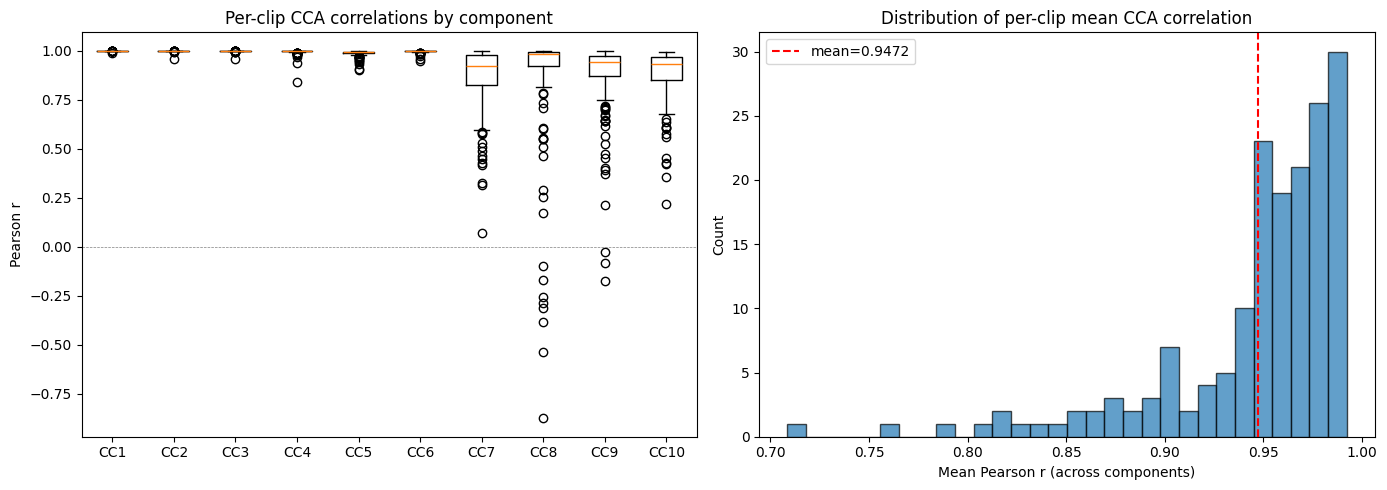

In [14]:
# Overall summary
mean_per_component = per_clip_corrs.mean(axis=0)
overall_mean = per_clip_corrs.mean()

print(f"=" * 60)
print(f"CCA Summary — {n_clips} test clips, {N_CCA_COMPONENTS} components")
print(f"=" * 60)
print(f"\n{'Component':<12} {'Mean r':>8} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 48)
for k in range(N_CCA_COMPONENTS):
    col = per_clip_corrs[:, k]
    print(
        f"CC{k + 1:<10} {col.mean():>8.4f} {col.std():>8.4f} {col.min():>8.4f} {col.max():>8.4f}"
    )
print("-" * 48)
print(f"{'Overall':<12} {overall_mean:>8.4f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot of per-clip correlations by component
axes[0].boxplot(
    [per_clip_corrs[:, k] for k in range(N_CCA_COMPONENTS)],
    labels=[f"CC{k + 1}" for k in range(N_CCA_COMPONENTS)],
)
axes[0].set_ylabel("Pearson r")
axes[0].set_title("Per-clip CCA correlations by component")
axes[0].axhline(y=0, color="gray", ls="--", lw=0.5)

# Mean correlation per clip (averaged across components)
mean_per_clip = per_clip_corrs.mean(axis=1)
axes[1].hist(mean_per_clip, bins=30, edgecolor="black", alpha=0.7)
axes[1].axvline(
    x=mean_per_clip.mean(),
    color="red",
    ls="--",
    lw=1.5,
    label=f"mean={mean_per_clip.mean():.4f}",
)
axes[1].set_xlabel("Mean Pearson r (across components)")
axes[1].set_ylabel("Count")
axes[1].set_title("Distribution of per-clip mean CCA correlation")
axes[1].legend()

plt.tight_layout()
plt.show()

## CCA: Fit Global Model (Decoder-Only)

Extract joint angles (strip first 7 root DoFs), concatenate across all test
clips, and fit a global CCA model.

In [11]:
ROOT_QPOS_SIZE = 7  # 3 position + 4 quaternion for root body

# Extract joint angles only
rollout_joints = all_rollout_qpos[:, :, ROOT_QPOS_SIZE:]  # (num_test, T, 67)
ref_joints = all_ref_qpos[:, :, ROOT_QPOS_SIZE:]  # (num_test, T, 67)

print(f"Joint angle shapes:")
print(f"  Rollout: {rollout_joints.shape}")
print(f"  Reference: {ref_joints.shape}")

# Concatenate across clips for global fit
n_clips, T, n_joints = rollout_joints.shape
X_concat = rollout_joints.reshape(-1, n_joints)  # (num_test * T, 67)
Y_concat = ref_joints.reshape(-1, n_joints)  # (num_test * T, 67)

print(f"\nConcatenated shapes for CCA fit:")
print(f"  X (rollout): {X_concat.shape}")
print(f"  Y (reference): {Y_concat.shape}")

# Fit CCA
cca = CCA(n_components=N_CCA_COMPONENTS)
cca.fit(X_concat, Y_concat)

# Compute canonical correlations on the full concatenated data
X_c_all, Y_c_all = cca.transform(X_concat, Y_concat)
global_corrs = []
for k in range(N_CCA_COMPONENTS):
    r, _ = pearsonr(X_c_all[:, k], Y_c_all[:, k])
    global_corrs.append(r)

print(f"\nGlobal canonical correlations ({N_CCA_COMPONENTS} components):")
for k, r in enumerate(global_corrs):
    print(f"  CC{k + 1}: {r:.4f}")

Joint angle shapes:
  Rollout: (168, 490, 67)
  Reference: (168, 490, 67)

Concatenated shapes for CCA fit:
  X (rollout): (82320, 67)
  Y (reference): (82320, 67)

Global canonical correlations (10 components):
  CC1: 0.9999
  CC2: 0.9997
  CC3: 0.9877
  CC4: 0.9998
  CC5: 0.9998
  CC6: 0.9754
  CC7: 1.0000
  CC8: 0.9647
  CC9: 0.9492
  CC10: 0.9391


## CCA: Per-Clip Correlations

Project each test clip individually using the global CCA weights, and
compute per-clip Pearson correlations for each canonical component.

In [12]:
per_clip_corrs = np.zeros((n_clips, N_CCA_COMPONENTS))

for i in range(n_clips):
    X_c, Y_c = cca.transform(rollout_joints[i], ref_joints[i])
    for k in range(N_CCA_COMPONENTS):
        r, _ = pearsonr(X_c[:, k], Y_c[:, k])
        per_clip_corrs[i, k] = r

print(f"Per-clip correlations shape: {per_clip_corrs.shape}")
print(f"\nPer-component summary (across {n_clips} clips):")
print(f"{'Component':<12} {'Mean':>8} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 48)
for k in range(N_CCA_COMPONENTS):
    col = per_clip_corrs[:, k]
    print(
        f"CC{k + 1:<10} {col.mean():>8.4f} {col.std():>8.4f} {col.min():>8.4f} {col.max():>8.4f}"
    )

Per-clip correlations shape: (168, 10)

Per-component summary (across 168 clips):
Component        Mean      Std      Min      Max
------------------------------------------------
CC1            0.9998   0.0003   0.9980   1.0000
CC2            0.9998   0.0002   0.9989   1.0000
CC3            0.9913   0.0129   0.8604   0.9995
CC4            0.9929   0.0246   0.7554   1.0000
CC5            0.9987   0.0022   0.9874   1.0000
CC6            0.8877   0.2356  -0.4238   0.9993
CC7            0.9996   0.0021   0.9753   1.0000
CC8            0.8535   0.1805   0.0845   0.9953
CC9            0.8728   0.1785  -0.0929   0.9982
CC10           0.9143   0.1523  -0.4676   0.9985


## Summary Statistics

CCA Summary — 168 test clips, 10 components

Component      Mean r      Std      Min      Max
------------------------------------------------
CC1            0.9998   0.0003   0.9980   1.0000
CC2            0.9998   0.0002   0.9989   1.0000
CC3            0.9913   0.0129   0.8604   0.9995
CC4            0.9929   0.0246   0.7554   1.0000
CC5            0.9987   0.0022   0.9874   1.0000
CC6            0.8877   0.2356  -0.4238   0.9993
CC7            0.9996   0.0021   0.9753   1.0000
CC8            0.8535   0.1805   0.0845   0.9953
CC9            0.8728   0.1785  -0.0929   0.9982
CC10           0.9143   0.1523  -0.4676   0.9985
------------------------------------------------
Overall        0.9510


/tmp/ipykernel_2544582/3934606985.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(


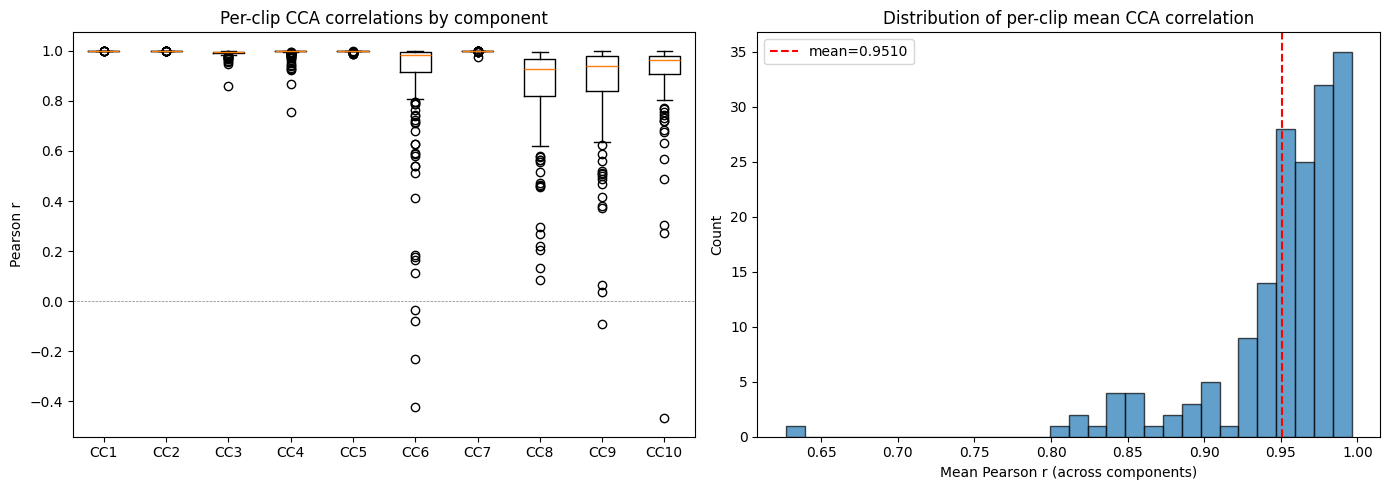

In [13]:
# Overall summary
mean_per_component = per_clip_corrs.mean(axis=0)
overall_mean = per_clip_corrs.mean()

print(f"=" * 60)
print(f"CCA Summary — {n_clips} test clips, {N_CCA_COMPONENTS} components")
print(f"=" * 60)
print(f"\n{'Component':<12} {'Mean r':>8} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 48)
for k in range(N_CCA_COMPONENTS):
    col = per_clip_corrs[:, k]
    print(
        f"CC{k + 1:<10} {col.mean():>8.4f} {col.std():>8.4f} {col.min():>8.4f} {col.max():>8.4f}"
    )
print("-" * 48)
print(f"{'Overall':<12} {overall_mean:>8.4f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot of per-clip correlations by component
axes[0].boxplot(
    [per_clip_corrs[:, k] for k in range(N_CCA_COMPONENTS)],
    labels=[f"CC{k + 1}" for k in range(N_CCA_COMPONENTS)],
)
axes[0].set_ylabel("Pearson r")
axes[0].set_title("Per-clip CCA correlations by component")
axes[0].axhline(y=0, color="gray", ls="--", lw=0.5)

# Mean correlation per clip (averaged across components)
mean_per_clip = per_clip_corrs.mean(axis=1)
axes[1].hist(mean_per_clip, bins=30, edgecolor="black", alpha=0.7)
axes[1].axvline(
    x=mean_per_clip.mean(),
    color="red",
    ls="--",
    lw=1.5,
    label=f"mean={mean_per_clip.mean():.4f}",
)
axes[1].set_xlabel("Mean Pearson r (across components)")
axes[1].set_ylabel("Count")
axes[1].set_title("Distribution of per-clip mean CCA correlation")
axes[1].legend()

plt.tight_layout()
plt.show()